# tiny-yolov4-voc sur voc — balayage lot × sous-ensemble

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/voc/tiny-yolov4-voc_sweep.ipynb)

Rôle : balayage lot × sous-ensemble ; palier **N** (6 runs de 600 itérations par défaut) ; chaque run est évalué sur `SUBSET` images, puis comparé aux autres. Tâches : [T24.6](../../docs/tasks/M24-yolov4-tiny.md), [T14.10](../../docs/tasks/M14-notebooks.md) ;
notebooks : [M14](../../docs/tasks/M14-notebooks.md).

Prérequis :
- données : `data/VOCdevkit/VOC2007/ImageSets/Main/test.txt` — tools/get_voc.sh
- poids : `weights/yolov4-tiny.weights` — tools/get_weights.sh

Chaque étape affiche la commande `python tools/…` qu'elle lance : un résultat se
reproduit en ligne de commande. Sorties dans `build/notebooks/voc/tiny-yolov4-voc/`, jamais dans `results/`
(une mAP sur `SUBSET` images n'est pas publiable, règles de M12). Notebook généré par
`python -m tools.notebooks` (`make notebooks`) : modifier le gabarit
`tools/notebooks/gabarits.py`, pas ce fichier.

## Paramètres

In [1]:
NET           = 'build/m11/cfg/tiny-yolov4-voc.cfg'  # nom de CFG_FILES ou cfg (relative à la racine)
DATASET       = 'voc'  # clé de DATASETS
SPLIT         = None  # None : split d'évaluation du jeu
WEIGHTS       = None  # par run : OUT/runs/<run>/final.weights
DEVICE        = 'gpu'  # cpu | gpu (entraînement seulement ; le reste sur CPU)
SUBSET        = 50  # images évaluées ; 0 : split complet (palier N)
SIZE          = None  # entrée LxH (ex. '640x192') ; None : celle de la cfg
RESIZE        = 'stretch'  # stretch (référence M12) | letterbox
METRIC        = None  # None : celle du jeu (coco pour coco et flir)
DATA_ROOT     = None  # racine du jeu ; None : data/<jeu> (Colab : dossier Drive)
BASE          = 'tiny-yolov4-coco'  # base de make_cfg.py
CHANNELS      = None  # canaux de la cfg (1 : thermique)
ANCHORS_K     = 6  # ancres de la cfg (6 : YOLOv4-tiny)
INIT          = 'weights/yolov4-tiny.weights'  # coco | he | chemin d'un .weights
INIT_NET      = 'tiny-yolov4-coco'  # réseau des poids de INIT s'il diffère de NET
BATCHES       = [8, 16, 32, 48]  # tailles de lot essayées
TRAIN_SUBSETS = [500, 0]  # images d'entraînement (n premières) ; 0 : tout le split
SEEDS         = [0]  # graines (train.py --seed) ; T15.2 : [1, 2]
ITERS         = 1200  # itérations par run (palier N dès 600)
SKIP_DONE     = True  # saute les runs qui ont déjà final.weights
LR            = 0.001
BURN_IN       = 500
MULTISCALE    = True  # 320-608 tous les 10 lots
SAVE_EVERY    = None  # None : défaut de train.py (200)
WORKERS       = 16
DRIVE_DIR     = '/content/drive/MyDrive/EmbeddedCV'  # Colab : archives data/<jeu>.tar, sorties et reprise dans runs/ ; None : pas de Drive
JOBS          = None  # processus des évaluations ; None : un par cœur CPU, plafonné par la mémoire (runtime TPU de Colab : des dizaines)
SHOW          = 6  # images affichées
OUT           = 'build/notebooks/voc/tiny-yolov4-voc'  # sorties du notebook
REPO_URL      = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab : dépôt cloné
REV           = 'main'  # Colab : révision

## Environnement

Local : rien n'est installé ni téléchargé, la cellule vérifie les prérequis et
s'arrête avec la commande à lancer. Colab : clone du dépôt, installation, CuPy si
`DEVICE = "gpu"`, poids, puis données par `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<jeu>.tar` ou téléchargement direct ; ExDark et FLIR : archive
seulement, faite sur le PC par `tools/get_datasets.sh pack <jeu>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone d'une session précédente : remis à REV (notebook et code du même commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules importés avant la mise à jour
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # Runtime CPU : pas de pilote, CuPy dirait « cudaErrorInsufficientDriver ».
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("runtime Colab sans GPU : créer un nouveau serveur Colab "
                               "de type GPU (T4, L4 ou A100), ou DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # version du pilote
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("racine du dépôt introuvable : ouvrir le notebook depuis notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, INIT if str(INIT).endswith('.weights') else 'weights/yolov3-tiny.weights' if INIT == 'coco' else (), None, DATA_ROOT, COLAB, hint='',
            drive_dir=DRIVE_DIR)
Path(OUT).mkdir(parents=True, exist_ok=True)

dépôt E:\EmbeddedComputervision @ 9a21d9a (modifié) ; Python 3.13.5 ; NumPy 2.5.4 ; backend gpu
GPU : 1 visible(s), CuPy 14.2.0
données voc : data/VOCdevkit/VOC2007/ImageSets/Main/test.txt ; poids : weights/yolov4-tiny.weights


## Préparation (jeux hors VOC)

Ancres k-means sur le split d'entraînement (`tools/kmeans_anchors.py`, table dans
`OUT`), puis cfg à N classes (`tools/make_cfg.py`), comme `tools/m11.sh <jeu>-prep`.
Sautée si la cfg existe déjà.

In [3]:
import csv
import json

import numpy as np
from IPython.display import Markdown, display
from PIL import Image

from tools.detect import draw
from tools.notebooks.matrice import estimate
from yolo.data import datasets
from yolo.data.letterbox import input_size, parse_size, size_label
from yolo.models.tiny_yolo import load_cfg

if not str(NET).endswith(".cfg"):
    print(f"{NET} : cfg du dépôt, pas de préparation")
elif Path(NET).exists():
    print(f"{NET} existe : préparation sautée")
else:
    anchors = Path(OUT) / f"anchors_{DATASET}{'_' + str(SIZE) if SIZE else ''}.md"
    C.run(C.cmd_anchors(DATASET, SIZE, anchors, DATA_ROOT))
    C.run(C.cmd_make_cfg(BASE, DATASET, C.anchors_k(anchors, ANCHORS_K), NET, SIZE,
                         CHANNELS))

build/m11/cfg/tiny-yolov4-voc.cfg existe : préparation sautée


## Aperçu des cibles

Quelques images augmentées (`yolo.data.loader.VOCDataset`, donc `yolo.data.augment`)
avec leurs boîtes : contrôle des annotations avant des heures de calcul.

16551 images d'entraînement, entrée 416×416, 3 canal(aux)


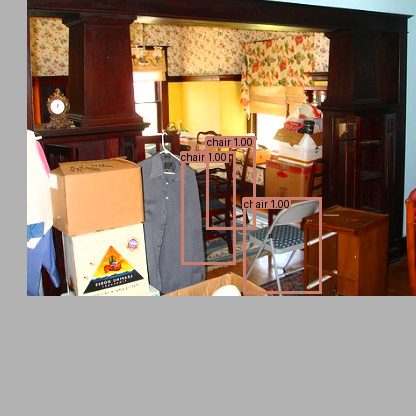

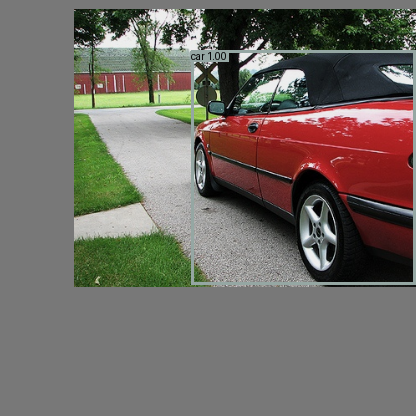

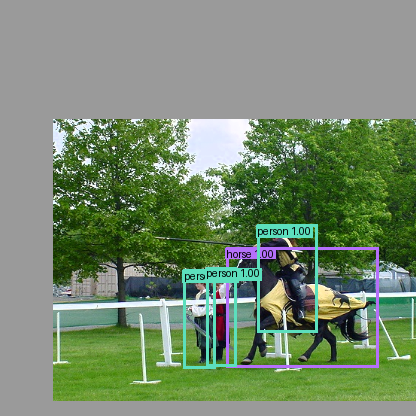

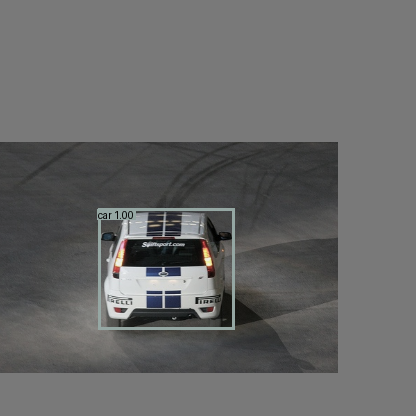

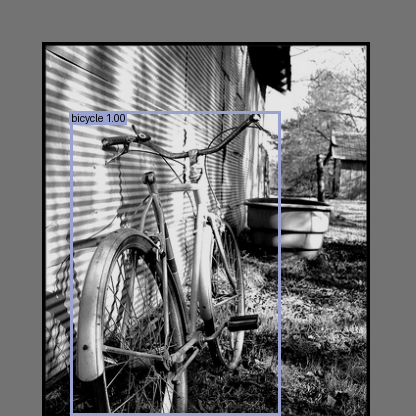

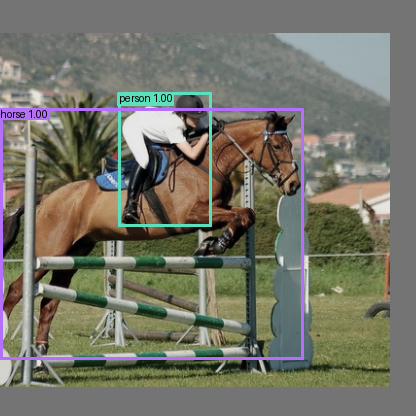

In [4]:
cfg = load_cfg(NET)
size = input_size(cfg, parse_size(SIZE) if SIZE else None)
channels = cfg["input"][0]
names = datasets.DATASETS[DATASET].classes
samples = datasets.load(DATASET, DATA_ROOT, role="train")
print(f"{len(samples)} images d'entraînement, entrée {size_label(size)}, {channels} canal(aux)")
from yolo.data.loader import VOCDataset

preview = VOCDataset(samples[:SHOW], train=True, channels=channels)
for k in range(len(preview)):
    chw, boxes, labels = preview.load(k, size, np.random.default_rng(k))
    hwc = (np.clip(chw.transpose(1, 2, 0), 0, 1) * 255).astype(np.uint8)
    img = Image.fromarray(hwc[..., 0] if channels == 1 else hwc)
    display(draw(img, boxes, np.ones(len(labels)), labels, names))

## Plan du balayage (T14.10)

Un run par case de la grille `BATCHES × TRAIN_SUBSETS × SEEDS`, tous les autres
paramètres égaux (ceux de `tools/m11.sh <jeu>-train`, `ITERS` à part).
`TRAIN_SUBSETS` prend les n premières images du split d'entraînement
(`train.py --subset`), 0 tout le split. Une graine non nulle (`train.py --seed` :
têtes, tirage des lots, multiscale) suffixe le run (`b32-sall-g1`) ; la graine 0
garde le nom court.
À itérations égales, un lot plus grand voit plus d'images : la colonne « époques »
le montre. Le taux d'apprentissage n'est pas ajusté au lot.

In [5]:
import threading

from tools.notebooks import colab, runs

PLAN = [(b, s, g, runs.run_name(b, s, g)) for b in BATCHES for s in TRAIN_SUBSETS
        for g in SEEDS]
rows = ["| run | lot | images | époques | durée estimée |", "|---|---|---|---|---|"]
total = 0
for b, s, g, name in PLAN:
    n = min(s, len(samples)) if s else len(samples)
    sec = estimate(ITERS, b, DEVICE)
    total += sec or 0
    done = (Path(OUT) / "runs" / name / "final.weights").exists()
    rows.append(f"| {name}{' (fait)' if done else ''} | {b} | {n} | "
                f"{ITERS * b / n:.2f} | "
                + (f"{sec / 3600:.1f} h |" if sec else "non mesurée |"))
display(Markdown("\n".join(rows)))
print(f"{len(PLAN)} runs de {ITERS} itérations"
      + (f", ≈ {total / 3600:.1f} h sur {DEVICE} au total" if total else ""))

| run | lot | images | époques | durée estimée |
|---|---|---|---|---|
| b8-s500 (fait) | 8 | 500 | 19.20 | 0.1 h |
| b8-sall | 8 | 16551 | 0.58 | 0.1 h |
| b16-s500 | 16 | 500 | 38.40 | 0.2 h |
| b16-sall | 16 | 16551 | 1.16 | 0.2 h |
| b32-s500 | 32 | 500 | 76.80 | 0.4 h |
| b32-sall | 32 | 16551 | 2.32 | 0.4 h |
| b48-s500 | 48 | 500 | 115.20 | 0.5 h |
| b48-sall | 48 | 16551 | 3.48 | 0.5 h |

8 runs de 1200 itérations, ≈ 2.3 h sur gpu au total


## Entraînements

Chaque run va dans `OUT/runs/<run>/` (`b16-sall`, `b8-s500`…), avec son `run.json`.
Relancer la cellule reprend le run interrompu (`--resume`) et saute ceux qui sont
finis (`SKIP_DONE`). Sur Colab avec `DRIVE_DIR`, `OUT` est copié dans
`<DRIVE_DIR>/runs/` toutes les 10 min et en fin de cellule (T14.8).

In [6]:
SYNC = COLAB and bool(DRIVE_DIR)
if SYNC:
    env.mount_drive(DRIVE_DIR)
    colab.restore_outputs(OUT, DRIVE_DIR)
stop = threading.Event()


def sync_loop(every=600):
    while not stop.wait(every):
        colab.sync_outputs(OUT, DRIVE_DIR)


if SYNC:
    threading.Thread(target=sync_loop, daemon=True).start()
try:
    for b, s, g, name in PLAN:
        run_dir = Path(OUT) / "runs" / name
        if SKIP_DONE and (run_dir / "final.weights").exists():
            print(f"{name} : déjà entraîné, sauté")
            continue
        resume = (run_dir / "checkpoint.npz").exists()
        runs.write_meta(run_dir, batch=b, subset=s, seed=g, iters=ITERS, lr=LR,
                        device=DEVICE, net=NET, dataset=DATASET, rev=TRACE["rev"])
        C.run(C.cmd_train(NET, run_dir, DATASET, INIT, INIT_NET, False, iters=ITERS,
                          batch=b, lr=LR, burn_in=BURN_IN, multiscale=MULTISCALE,
                          subset=s, save_every=SAVE_EVERY, workers=WORKERS,
                          device=DEVICE, data_root=DATA_ROOT, seed=g),
              log=run_dir / "log.txt")
finally:
    stop.set()
    if SYNC:
        colab.sync_outputs(OUT, DRIVE_DIR)

b8-s500 : déjà entraîné, sauté
$ python tools/train.py --net build/m11/cfg/tiny-yolov4-voc.cfg --init weights/yolov4-tiny.weights --init-net tiny-yolov4-coco --iters 1200 --batch 8 --lr 0.001 --burn-in 500 --multiscale --workers 16 --device gpu --out 'build\notebooks\voc\tiny-yolov4-voc\runs\b8-sall'
poids yolov4-tiny.weights copiÃ©s ; couches rÃ©initialisÃ©es : [29, 36]
backend : gpu
16551 images, 2068 lots par Ã©poque
it      1  lr 1.60e-14  perte 4704.636  coord 35.602 obj 1.304 noobj 4620.572 cls 47.158
it      2  lr 2.56e-13  perte 4749.153  coord 16.586 obj 1.443 noobj 4693.766 cls 37.358
it      3  lr 1.30e-12  perte 4745.780  coord 16.386 obj 2.036 noobj 4687.159 cls 40.198
it      4  lr 4.10e-12  perte 4711.158  coord 17.581 obj 2.221 noobj 4642.843 cls 48.513
it      5  lr 1.00e-11  perte 4644.068  coord 15.066 obj 1.993 noobj 4587.291 cls 39.718
it      6  lr 2.07e-11  perte 4747.750  coord 24.163 obj 1.014 noobj 4691.697 cls 30.876
it      7  lr 3.84e-11  perte 4734.509  co

## Comparaison

mAP flottante de chaque run sur les mêmes `SUBSET` images (`tools/eval_voc.py`,
dans `OUT/eval/<run>/`, cache partagé avec la comparaison des notebooks `_infer` :
réutilisée si déjà calculée), perte finale et vitesse ; courbes de perte superposées
(`tools.figures.resultats.plot_training`, M13). Les notebooks d'inférence
`<modèle>_infer` lisent ces runs (`RUN`, `COMPARE`).

$ python tools/eval_voc.py --net build/m11/cfg/tiny-yolov4-voc.cfg --weights 'build\notebooks\voc\tiny-yolov4-voc\runs\b16-s500\final.weights' --dataset voc --resize stretch --subset 50 --out 'build\notebooks\voc\tiny-yolov4-voc\eval\b16-s500\dets_s50' --markdown 'build\notebooks\voc\tiny-yolov4-voc\eval\b16-s500\map_float_s50.md' --jobs 16
50/50 images       2 s  (48 ms/image)
dÃ©tections : build\notebooks\voc\tiny-yolov4-voc\eval\b16-s500\dets_s50
### build/m11/cfg/tiny-yolov4-voc.cfg (final.weights), VOC2007 test, 50 images, 416Ã—416 stretch (pil), conf 0.005, NMS 0.45, AP 11 points

| Classe | AP |
|---|---|
| aeroplane | 100.0 |
| bicycle | 54.5 |
| bird | 34.6 |
| boat | 18.2 |
| bottle | 0.0 |
| bus | 59.9 |
| car | 52.7 |
| cat | 58.0 |
| chair | 41.4 |
| cow | 28.6 |
| diningtable | 27.3 |
| dog | 23.0 |
| horse | 100.0 |
| motorbike | 40.6 |
| person | 54.5 |
| pottedplant | 0.0 |
| sheep | 100.0 |
| sofa | 0.0 |
| train | 72.7 |
| tvmonitor | 0.0 |
| **mAP** | **43.30** |

f

| run | lot | images | graine | itérations | géométrie | backend | perte finale | mAP | s/image | éval. |
|---|---|---|---|---|---|---|---|---|---|---|
| b48-sall | 48 | tout | 0 | 1200 | letterbox | gpu | 8.14 | 56.31 | 0.01 | 50 |
| b32-sall | 32 | tout | 0 | 1200 | letterbox | gpu | 9.25 | 55.65 | 0.01 | 50 |
| b48-s500 | 48 | 500 | 0 | 1200 | letterbox | gpu | 4.31 | 46.71 | 0.01 | 50 |
| b32-s500 | 32 | 500 | 0 | 1200 | letterbox | gpu | 5.35 | 44.91 | 0.01 | 50 |
| b16-s500 | 16 | 500 | 0 | 1200 | letterbox | gpu | 6.72 | 43.30 | 0.01 | 50 |
| b16-sall | 16 | tout | 0 | 1200 | letterbox | gpu | 9.82 | 39.20 | 0.01 | 50 |
| b8-sall | 8 | tout | 0 | 1200 | letterbox | gpu | 10.97 | 33.09 | 0.01 | 50 |
| b8-s500 | 8 | 500 | 0 | 600 | letterbox | gpu | 10.54 | 19.85 | 0.06 | 50 |

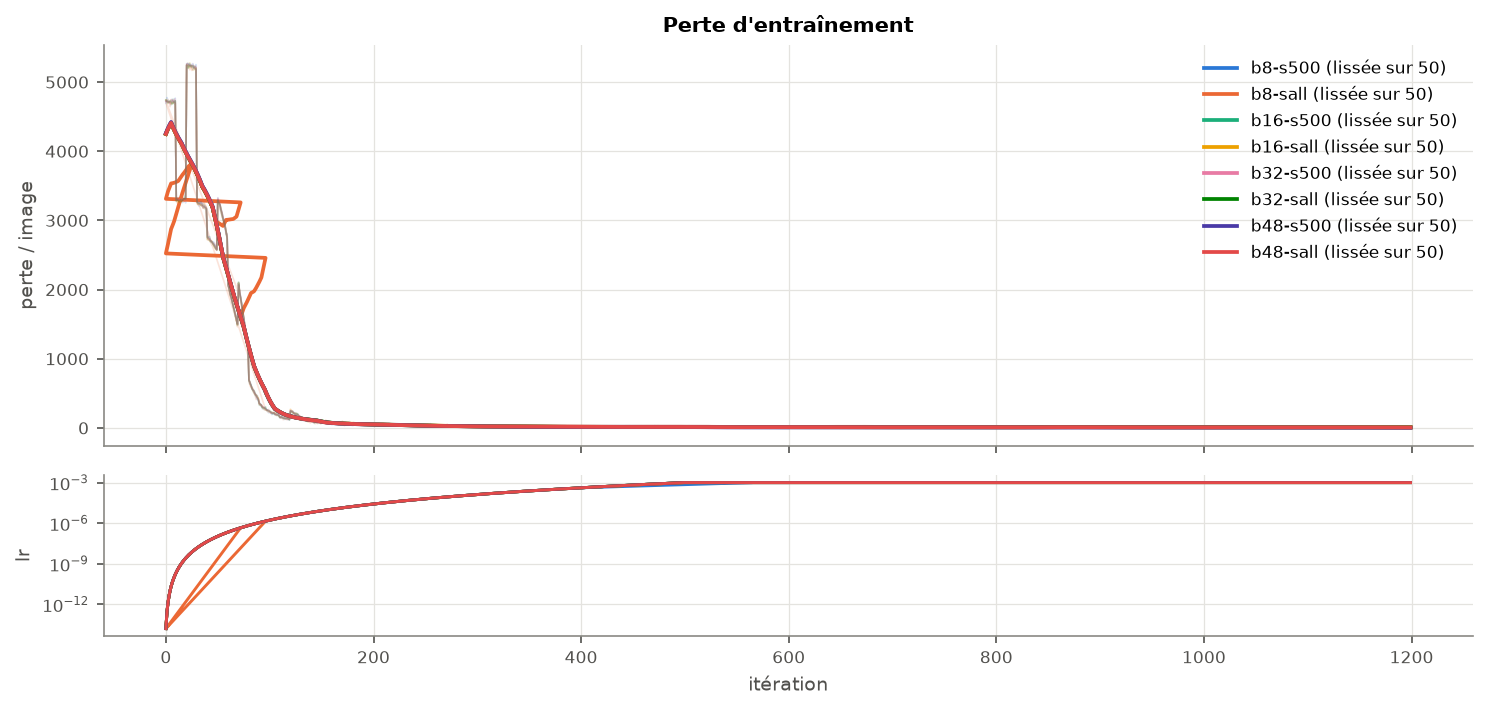

In [7]:
from tools.figures import MissingSource
from tools.figures import resultats as FR

RESULTS = [runs.evaluate(r, NET, DATASET, RESIZE, SUBSET, METRIC, SPLIT, SIZE, DATA_ROOT,
                         out_dir=f"{OUT}/eval/{r.name}", jobs=JOBS)
           for r in runs.find_runs(OUT) if r.name != runs.TRAIN]
display(Markdown(runs.table(RESULTS)))
curves = []
for b, s, g, name in PLAN:
    try:
        curves.append(FR.load_training(Path(OUT) / "runs" / name))
    except MissingSource:
        pass
if curves:
    for png in FR.plot_training(curves, Path(OUT) / "figures", "balayage"):
        if str(png).endswith(".png"):
            display(Image.open(png))

## Résumé

In [8]:
print(f"runs : {OUT}/runs/ ; backend {DEVICE} ; révision {TRACE['rev']}")
best = max((r for r in RESULTS if r["mAP"] is not None), key=lambda r: r["mAP"],
           default=None)
if best:
    print(f"meilleur run sur {SUBSET or 'toutes les'} images : {best['run']} "
          f"(mAP {best['mAP']:.2f}) ; inférence : RUN = {best['run']!r}")
print("commandes équivalentes :")
for c in C.HISTORY:
    print("  " + c)

runs : build/notebooks/voc/tiny-yolov4-voc/runs/ ; backend gpu ; révision 9a21d9a
meilleur run sur 50 images : b48-sall (mAP 56.31) ; inférence : RUN = 'b48-sall'
commandes équivalentes :
  python tools/train.py --net build/m11/cfg/tiny-yolov4-voc.cfg --init weights/yolov4-tiny.weights --init-net tiny-yolov4-coco --iters 1200 --batch 8 --lr 0.001 --burn-in 500 --multiscale --workers 16 --device gpu --out 'build\notebooks\voc\tiny-yolov4-voc\runs\b8-sall'
  python tools/train.py --net build/m11/cfg/tiny-yolov4-voc.cfg --init weights/yolov4-tiny.weights --init-net tiny-yolov4-coco --iters 1200 --batch 16 --lr 0.001 --burn-in 500 --multiscale --subset 500 --workers 16 --device gpu --out 'build\notebooks\voc\tiny-yolov4-voc\runs\b16-s500'
  python tools/train.py --net build/m11/cfg/tiny-yolov4-voc.cfg --init weights/yolov4-tiny.weights --init-net tiny-yolov4-coco --iters 1200 --batch 16 --lr 0.001 --burn-in 500 --multiscale --workers 16 --device gpu --out 'build\notebooks\voc\tiny-yolov4-v